# Analisis 9 Dataset: Binary, Multi-class, dan Multi-label Classification

**Mata kuliah:** Machine Learning (Semester 5)
**Nama / NIM:** _(isi sendiri)_

Notebook ini berisi:
1. Penjelasan singkat 3 jenis klasifikasi
2. Membuka 9 file ZIP dan membaca datasetnya dengan Pandas
3. Memeriksa isi tiap dataset (baris, kolom, contoh data, data kosong)
4. Memeriksa kolom label dan nilai uniknya
5. Pembagian 9 dataset ke 3 jenis klasifikasi, lengkap dengan alasannya
6. Perbandingan, kesimpulan, dan referensi (2023-2026)

> Catatan: tugas ini hanya **mengidentifikasi dataset**, jadi tidak ada proses training model.

## 1. Tiga jenis klasifikasi

| Jenis | Artinya | Jumlah kelas | Satu data punya berapa label? | Contoh |
|---|---|---|---|---|
| **Binary** | Memilih salah satu dari **2** pilihan | 2 | 1 | Film atau Serial TV, Spam atau Bukan |
| **Multi-class** | Memilih salah satu dari **3 atau lebih** pilihan | 3+ | 1 | Genre game: Racing / Horror / Puzzle / ... |
| **Multi-label** | Boleh memilih **lebih dari satu** label sekaligus | 2+ | 1 atau lebih | Film bergenre "Action, Adventure, Thriller" |

Cara mudah membedakannya:
- Kalau jawabannya cuma **ya / tidak** atau **A / B**, itu **binary**.
- Kalau jawabannya **satu dari banyak pilihan**, itu **multi-class**.
- Kalau jawabannya **boleh lebih dari satu sekaligus**, itu **multi-label**.

## 2. Daftar 9 dataset dan pembagiannya

Pembagian ini dibuat **setelah memeriksa isi kolom dan nilai labelnya** (lihat bagian 5 sampai 7), bukan asal pilih.

| No | Dataset | File CSV | Jenis | Kolom label |
|---|---|---|---|---|
| 1 | NetFlix | `NetFlix.csv` | Binary | `type` (Movie / TV Show) |
| 2 | Total Anime Movie Releases 2027 | `total_anime_movie_releases_2027_dataset.csv` | Binary | `is_franchise_sequel` (0 / 1) |
| 3 | One Piece Live Action IMDB Reviews | `reviews.csv` | Binary | `label_sentimen` (**label turunan** dari `Rating`) |
| 4 | Cars Datasets 2025 | `Cars Datasets 2025.csv` | Multi-class | `kelompok_bahan_bakar` (**label turunan** dari `Fuel Types`) |
| 5 | Top Games Dataset | `games_dataset.csv` | Multi-class | `Genre` (14 kelas) |
| 6 | Kobe Beef Global Distribution | `kobe_beef_distribution (5).csv` | Multi-class | `Country` (26 negara tujuan) |
| 7 | Movie Genres Overview | `movies.csv` | Multi-label | `genre` (satu film punya beberapa genre, **label turunan**: teks list dipecah) |
| 8 | Movie Dataset with IDs and Genre Tags | `movie_metadata_genres.csv` | Multi-label | `genres` (genre dipisah tanda `|`) |
| 9 | Board Games Dataset | `board_games.csv` | Multi-label | `category` (kategori game dipisah koma) |

## 3. Persiapan: import library dan ekstrak file ZIP

In [ ]:
import re
import zipfile
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 40)
pd.set_option("display.width", 200)

Taruh **9 file ZIP** di folder yang sama dengan notebook ini. Kalau ZIP-nya ada di folder lain, ubah `ZIP_FOLDER` di bawah.
Hasil ekstrak akan disimpan otomatis di folder `data_ekstrak`.

In [2]:
ZIP_FOLDER = Path(".")                 # ubah kalau file ZIP ada di folder lain
EKSTRAK_FOLDER = Path("data_ekstrak")  # folder hasil ekstrak (dibuat otomatis)
EKSTRAK_FOLDER.mkdir(exist_ok=True)

file_zip = sorted(ZIP_FOLDER.glob("*.zip"))
print(f"Ditemukan {len(file_zip)} file ZIP:\n")

for z in file_zip:
    with zipfile.ZipFile(z) as arsip:
        arsip.extractall(EKSTRAK_FOLDER / z.stem)
    print("Diekstrak :", z.name)

Ditemukan 9 file ZIP:

Diekstrak : Board Games Dataset.zip
Diekstrak : Cars Datasets (2025).zip
Diekstrak : Kobe Beef Global Distribution.zip
Diekstrak : Movie Dataset with IDs and Genre Tags.zip
Diekstrak : Movie Genres Overview.zip
Diekstrak : NetFlix.zip
Diekstrak : One Piece Live Action IMDB Reviews.zip
Diekstrak : Top Games Dataset.zip
Diekstrak : Total Anime Movie Releases in 2027.zip


## 4. Fungsi bantu
Fungsi-fungsi ini dipakai berulang untuk 9 dataset supaya kodenya rapi.

In [3]:
ringkasan = []   # tabel perbandingan akan diisi otomatis di tiap dataset


def baca_csv(nama_csv):
    """Cari file CSV di folder ekstrak lalu baca dengan Pandas."""
    hasil = list(EKSTRAK_FOLDER.rglob(nama_csv))
    if not hasil:
        raise FileNotFoundError(f"File {nama_csv} tidak ditemukan. Cek file ZIP-nya.")
    try:
        return pd.read_csv(hasil[0])
    except UnicodeDecodeError:           # beberapa file memakai encoding lain
        return pd.read_csv(hasil[0], encoding="latin-1")


def info_dasar(df, kolom_contoh=None):
    """Tampilkan jumlah baris, kolom, nama kolom, contoh data, dan data kosong."""
    print(f"Jumlah baris : {df.shape[0]}")
    print(f"Jumlah kolom : {df.shape[1]}")
    print("Nama kolom   :", list(df.columns))
    print("\nContoh 3 baris pertama:")
    display(df.head(3) if kolom_contoh is None else df[kolom_contoh].head(3))
    kosong = df.isna().sum()
    kosong = kosong[kosong > 0]
    print("\nData kosong (NaN) per kolom:")
    if kosong.empty:
        print("Tidak ada data kosong.")
    else:
        display(kosong.to_frame("jumlah_kosong"))


def cek_label(seri, judul, maks=15):
    """Untuk binary dan multi-class: tampilkan nilai unik dan jumlah tiap kelas."""
    print(f"Kolom label : {seri.name}")
    print(f"Jumlah kelas: {seri.nunique()}")
    print("Nilai unik  :", sorted(seri.dropna().unique().tolist(), key=str)[:maks])
    jumlah = seri.value_counts()
    tabel = pd.DataFrame({"jumlah": jumlah, "persen": (jumlah / jumlah.sum() * 100).round(1)})
    print("\nJumlah data tiap kelas:")
    display(tabel.head(maks))
    jumlah.head(maks).sort_values().plot(kind="barh", figsize=(7, 0.35 * min(len(jumlah), maks) + 1.5))
    plt.title(judul)
    plt.xlabel("Jumlah data")
    plt.tight_layout()
    plt.show()


def cek_multilabel(daftar_label, judul, maks=10):
    """Untuk multi-label: daftar_label = Series yang tiap selnya berisi LIST label.
    List dipecah menjadi kolom 0/1 untuk tiap label."""
    daftar_label = daftar_label[daftar_label.str.len() > 0]            # buang baris tanpa label
    matriks = pd.get_dummies(daftar_label.explode()).groupby(level=0).max().astype(int)
    per_baris = matriks.sum(axis=1)
    print(f"Kolom label              : {daftar_label.name}")
    print(f"Jumlah data yang dipakai : {len(matriks)}")
    print(f"Jumlah label unik        : {matriks.shape[1]}")
    print(f"Rata-rata label per data : {per_baris.mean():.2f}")
    print(f"Paling banyak label/data : {per_baris.max()}")
    print(f"Data dengan >1 label     : {(per_baris > 1).mean() * 100:.1f}%")
    print(f"\n{maks} label paling sering muncul:")
    top = matriks.sum().sort_values(ascending=False).head(maks)
    display(top.to_frame("jumlah"))
    top.sort_values().plot(kind="barh", figsize=(7, 4))
    plt.title(judul)
    plt.xlabel("Jumlah data")
    plt.tight_layout()
    plt.show()
    return matriks, per_baris


def catat(no, nama, jenis, kolom_label, jumlah_kelas, baris, catatan=""):
    ringkasan.append({"No": no, "Dataset": nama, "Jenis": jenis, "Kolom label": kolom_label,
                      "Jumlah kelas/label": jumlah_kelas, "Jumlah baris": baris, "Catatan": catatan})

---
## 5. BINARY CLASSIFICATION (2 kelas)
Label hanya punya **2 nilai**. Datanya masuk ke salah satu dari dua kelas.

### 5.1 NetFlix
**Isi dataset:** daftar film dan serial TV di Netflix (judul, sutradara, pemeran, negara, tahun rilis, rating usia, durasi, genre, deskripsi).

**Kolom label:** `type` — hanya berisi `Movie` dan `TV Show`, jadi **binary**.

In [4]:
df_netflix = baca_csv("NetFlix.csv")
info_dasar(df_netflix)

Jumlah baris : 7787
Jumlah kolom : 12
Nama kolom   : ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'genres', 'description']

Contoh 3 baris pertama:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Miche...",Brazil,14-Aug-20,2020,TV-MA,4,"International TV Shows, TV Dramas, T...",In a future where the elite inhabit ...
1,s10,Movie,1920,Vikram Bhatt,"Rajneesh Duggal, Adah Sharma, Indran...",India,15-Dec-17,2008,TV-MA,143,"Horror Movies, International Movies,...",An architect and his wife move into ...
2,s100,Movie,3 Heroines,Iman Brotoseno,"Reza Rahadian, Bunga Citra Lestari, ...",Indonesia,5-Jan-19,2016,TV-PG,124,"Dramas, International Movies, Sports...",Three Indonesian women break records...



Data kosong (NaN) per kolom:


,jumlah_kosong
director,2389
cast,718
country,507
date_added,10
rating,7


Kolom label : type
Jumlah kelas: 2
Nilai unik  : ['Movie', 'TV Show']

Jumlah data tiap kelas:


,jumlah,persen
type,,
Movie,5377,69.1
TV Show,2410,30.9


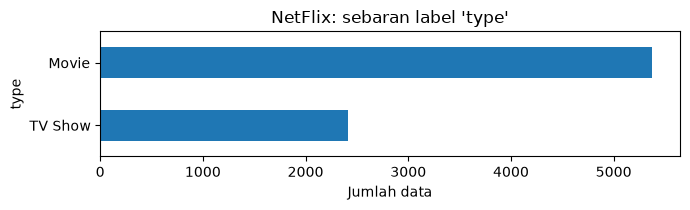

In [5]:
cek_label(df_netflix["type"], "NetFlix: sebaran label 'type'")
catat(1, "NetFlix", "Binary", "type", df_netflix["type"].nunique(), len(df_netflix),
      "Movie vs TV Show (tidak seimbang)")

**Alasan:** kolom `type` hanya punya 2 nilai unik, yaitu `Movie` dan `TV Show`. Setiap judul pasti salah satunya, tidak mungkin keduanya.
Jumlah `Movie` lebih banyak daripada `TV Show` (data tidak seimbang).

### 5.2 Total Anime Movie Releases 2027
**Isi dataset:** data film anime yang rencananya rilis tahun 2027 (anggaran produksi, minggu rilis, jumlah bioskop, popularitas bahan sumber, genre, tingkat studio, bahan sumber, dll).

**Kolom label:** `is_franchise_sequel` — berisi `0` (bukan sekuel) dan `1` (sekuel franchise), jadi **binary**.

In [6]:
df_anime = baca_csv("total_anime_movie_releases_2027_dataset.csv")
info_dasar(df_anime)

Jumlah baris : 1000
Jumlah kolom : 10
Nama kolom   : ['production_budget_million_usd', 'week_of_year', 'theater_count_release', 'source_material_popularity_score', 'genre', 'studio_tier', 'source_material', 'is_franchise_sequel', 'international_release', 'total_anime_movie_releases']

Contoh 3 baris pertama:


,production_budget_million_usd,week_of_year,theater_count_release,source_material_popularity_score,genre,studio_tier,source_material,is_franchise_sequel,international_release,total_anime_movie_releases
0,4.54,10,844,70.9,Fantasy,Mid-Tier,Manga,0,0,10
1,17.56,11,497,49.8,Sci-Fi,Mid-Tier,Original,1,0,10
2,5.75,31,659,36.8,Fantasy,A-List,Manga,1,1,11



Data kosong (NaN) per kolom:


,jumlah_kosong
genre,1


Kolom label : is_franchise_sequel
Jumlah kelas: 2
Nilai unik  : [0, 1]

Jumlah data tiap kelas:


,jumlah,persen
is_franchise_sequel,,
0,613,61.3
1,387,38.7


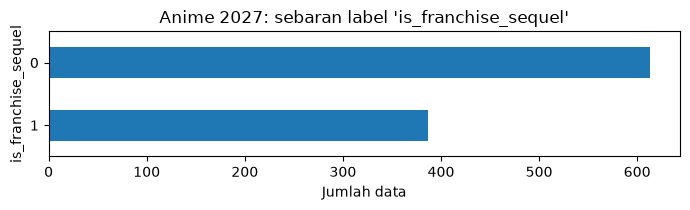

Arti nilai: 0 = bukan sekuel franchise, 1 = sekuel franchise


In [7]:
cek_label(df_anime["is_franchise_sequel"], "Anime 2027: sebaran label 'is_franchise_sequel'")
print("Arti nilai: 0 = bukan sekuel franchise, 1 = sekuel franchise")
catat(2, "Total Anime Movie Releases 2027", "Binary", "is_franchise_sequel",
      df_anime["is_franchise_sequel"].nunique(), len(df_anime), "0 = bukan sekuel, 1 = sekuel")

**Alasan:** kolom `is_franchise_sequel` sudah berbentuk 0/1, jadi tidak perlu diubah.
Kolom `total_anime_movie_releases` tidak dipilih karena isinya angka jumlah rilis, bukan kategori.

### 5.3 One Piece Live Action IMDB Reviews
**Isi dataset:** ulasan penonton serial live action One Piece di IMDb (judul ulasan, isi ulasan, tanggal, rating 1 sampai 10).

**Masalah:** kolom `Rating` berisi angka 1 sampai 10, bukan 2 kelas. Kalau langsung dipakai, itu bukan binary.
Jadi dibuat **label turunan** bernama `label_sentimen`.

In [8]:
df_reviews = baca_csv("reviews.csv")
info_dasar(df_reviews)
print("\nNilai unik kolom Rating (sebelum diubah):")
display(df_reviews["Rating"].value_counts().sort_index().to_frame("jumlah"))

Jumlah baris : 878
Jumlah kolom : 4
Nama kolom   : ['Title', 'Review', 'Date', 'Rating']

Contoh 3 baris pertama:


,Title,Review,Date,Rating
0,Never seen the anime and still enjoy...,I have to admit that I've never watc...,4 September 2023,8.0
1,Not My Kind of Show. But This I Loved.,I'm a 60yo man & old school like the...,4 September 2023,9.0
2,I'm Shocked By How Good This Is...,Every live action anime that I've br...,1 September 2023,9.0



Data kosong (NaN) per kolom:


,jumlah_kosong
Rating,8



Nilai unik kolom Rating (sebelum diubah):


,jumlah
Rating,
1.0,27
2.0,13
3.0,17
4.0,12
5.0,27
6.0,26
7.0,52
8.0,93
9.0,171


**Aturan pembuatan label turunan:**
- Rating **7 sampai 10** → `Positif`
- Rating **1 sampai 6** → `Negatif`
- Baris yang Rating-nya kosong **dibuang** karena tidak bisa diberi label.

Baris dibuang karena Rating kosong: 8
Kolom label : label_sentimen
Jumlah kelas: 2
Nilai unik  : ['Negatif', 'Positif']

Jumlah data tiap kelas:


,jumlah,persen
label_sentimen,,
Positif,748,86.0
Negatif,122,14.0


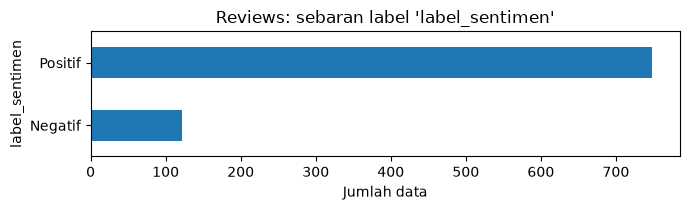

In [9]:
df_reviews_bersih = df_reviews.dropna(subset=["Rating"]).copy()
df_reviews_bersih["label_sentimen"] = df_reviews_bersih["Rating"].apply(
    lambda r: "Positif" if r >= 7 else "Negatif"
)
print(f"Baris dibuang karena Rating kosong: {len(df_reviews) - len(df_reviews_bersih)}")
cek_label(df_reviews_bersih["label_sentimen"], "Reviews: sebaran label 'label_sentimen'")
catat(3, "One Piece Live Action IMDB Reviews", "Binary", "label_sentimen (turunan dari Rating)",
      df_reviews_bersih["label_sentimen"].nunique(), len(df_reviews_bersih),
      "Positif (rating 7-10) vs Negatif (rating 1-6)")

**Alasan:** setelah diubah, labelnya tinggal 2 nilai (`Positif` dan `Negatif`), jadi cocok untuk **binary**.
Terlihat ulasan positif jauh lebih banyak daripada negatif.

---
## 6. MULTI-CLASS CLASSIFICATION (3 kelas atau lebih, pilih satu)
Label punya **banyak pilihan**, tetapi setiap data hanya masuk ke **satu** kelas.

### 6.1 Cars Datasets 2025
**Isi dataset:** data mobil tahun 2025 (merek, nama mobil, mesin, kapasitas, tenaga, kecepatan, harga, jenis bahan bakar, jumlah kursi, torsi).

**Masalah:** kolom `Fuel Types` kotor. Ada banyak penulisan berbeda untuk hal yang mirip, misalnya `Petrol/Hybrid`, `Hybrid (Petrol)`, `plug in hyrbrid` (salah ketik), dan `Diesel/Petrol`.
Jadi dibuat **label turunan** `kelompok_bahan_bakar`.

In [10]:
df_cars = baca_csv("Cars Datasets 2025.csv")
info_dasar(df_cars)
print("\nNilai unik 'Fuel Types' asli:", df_cars["Fuel Types"].nunique())
display(df_cars["Fuel Types"].value_counts().head(10).to_frame("jumlah"))

Jumlah baris : 1218
Jumlah kolom : 11
Nama kolom   : ['Company Names', 'Cars Names', 'Engines', 'CC/Battery Capacity', 'HorsePower', 'Total Speed', 'Performance(0 - 100 )KM/H', 'Cars Prices', 'Fuel Types', 'Seats', 'Torque']

Contoh 3 baris pertama:


,Company Names,Cars Names,Engines,CC/Battery Capacity,HorsePower,Total Speed,Performance(0 - 100 )KM/H,Cars Prices,Fuel Types,Seats,Torque
0,FERRARI,SF90 STRADALE,V8,3990 cc,963 hp,340 km/h,2.5 sec,"$1,100,000",plug in hyrbrid,2,800 Nm
1,ROLLS ROYCE,PHANTOM,V12,6749 cc,563 hp,250 km/h,5.3 sec,"$460,000",Petrol,5,900 Nm
2,Ford,KA+,1.2L Petrol,"1,200 cc",70-85 hp,165 km/h,10.5 sec,"$12,000-$15,000",Petrol,5,100 - 140 Nm



Data kosong (NaN) per kolom:


,jumlah_kosong
CC/Battery Capacity,3
Performance(0 - 100 )KM/H,6
Torque,1



Nilai unik 'Fuel Types' asli: 23


,jumlah
Fuel Types,
Petrol,871
Diesel,106
Electric,97
Hybrid,79
Petrol/Diesel,16
Petrol/Hybrid,16
Plug-in Hybrid,5
Diesel/Petrol,4
Hybrid (Petrol),4


**Aturan pembuatan label turunan** (dicek berurutan dari atas):
1. Kata `AWD` dibuang dulu karena itu jenis penggerak, bukan bahan bakar.
2. Ada kata `hybrid` / `hyrbrid` / `plug`, atau ada tanda `/`, `,`, `+` (campuran) → **Hybrid/Campuran**
3. Mengandung `petrol` atau `gas` → **Petrol**
4. Mengandung `diesel` → **Diesel**
5. Mengandung `electric` → **Electric**
6. Selain itu (misalnya `Hydrogen`) → **Lainnya**

Kolom label : kelompok_bahan_bakar
Jumlah kelas: 5
Nilai unik  : ['Diesel', 'Electric', 'Hybrid/Campuran', 'Lainnya', 'Petrol']

Jumlah data tiap kelas:


,jumlah,persen
kelompok_bahan_bakar,,
Petrol,873,71.7
Hybrid/Campuran,139,11.4
Diesel,106,8.7
Electric,97,8.0
Lainnya,3,0.2


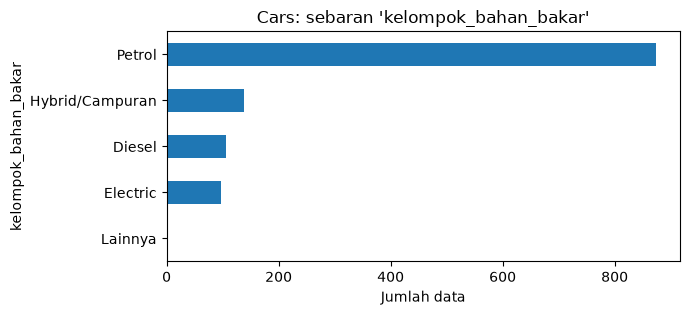

In [11]:
def kelompok_bahan_bakar(teks):
    t = re.sub(r"[/ ,]*awd", "", str(teks).lower())      # buang AWD
    if any(k in t for k in ["hybrid", "hyrbrid", "plug", "/", ",", "+"]):
        return "Hybrid/Campuran"
    if "petrol" in t or "gas" in t:
        return "Petrol"
    if "diesel" in t:
        return "Diesel"
    if "electric" in t:
        return "Electric"
    return "Lainnya"


df_cars["kelompok_bahan_bakar"] = df_cars["Fuel Types"].apply(kelompok_bahan_bakar)
cek_label(df_cars["kelompok_bahan_bakar"], "Cars: sebaran 'kelompok_bahan_bakar'")
catat(4, "Cars Datasets 2025", "Multi-class", "kelompok_bahan_bakar (turunan dari Fuel Types)",
      df_cars["kelompok_bahan_bakar"].nunique(), len(df_cars),
      "Petrol / Diesel / Electric / Hybrid-Campuran / Lainnya")

**Alasan:** setelah dirapikan ada 5 kelompok, dan satu mobil hanya masuk ke satu kelompok. Jadi ini **multi-class**.
Kelas `Petrol` paling banyak, sedangkan `Lainnya` sangat sedikit (data tidak seimbang).

### 6.2 Top Games Dataset
**Isi dataset:** daftar 5.000 game (nama, genre, platform, tahun rilis, rating pengguna).

**Kolom label:** `Genre` — setiap game hanya punya **satu** genre, tetapi pilihan genrenya banyak (14 jenis). Jadi **multi-class**.

In [12]:
df_games = baca_csv("games_dataset.csv")
info_dasar(df_games)

Jumlah baris : 5000
Jumlah kolom : 5
Nama kolom   : ['Game Name', 'Genre', 'Platform', 'Release Year', 'User Rating']

Contoh 3 baris pertama:


,Game Name,Genre,Platform,Release Year,User Rating
0,Sekiro: Shadows Die Twice,Sports,Nintendo Switch,2014,9.654719
1,Control,Puzzle,Nintendo Switch,2000,3.457386
2,Among Us,Strategy,Nintendo Switch,2007,5.367622



Data kosong (NaN) per kolom:
Tidak ada data kosong.


Kolom label : Genre
Jumlah kelas: 14
Nilai unik  : ['Action', 'Adventure', 'Fighting', 'Horror', 'Platformer', 'Puzzle', 'Racing', 'Role-playing', 'Shooter', 'Simulation', 'Sports', 'Stealth', 'Strategy', 'Survival']

Jumlah data tiap kelas:


,jumlah,persen
Genre,,
Sports,403,8.1
Puzzle,384,7.7
Racing,369,7.4
Simulation,368,7.4
Stealth,360,7.2
Role-playing,360,7.2
Horror,356,7.1
Strategy,353,7.1
Survival,353,7.1


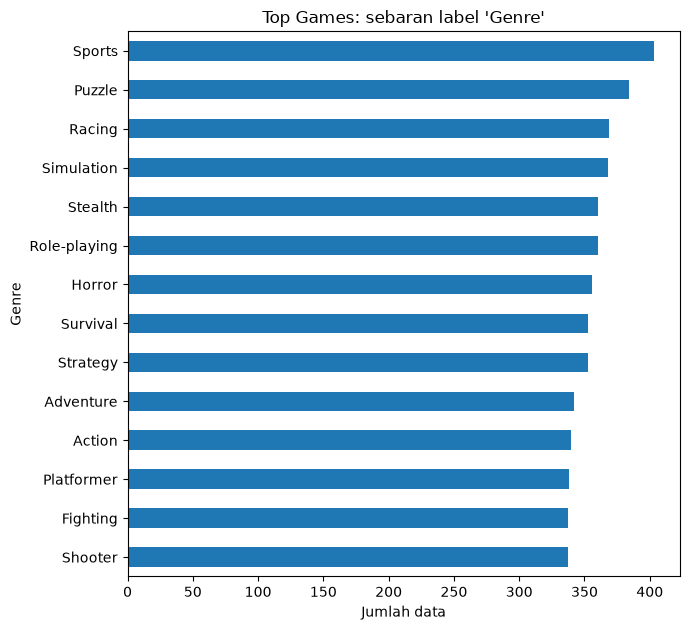

In [13]:
cek_label(df_games["Genre"], "Top Games: sebaran label 'Genre'")
catat(5, "Top Games Dataset", "Multi-class", "Genre", df_games["Genre"].nunique(), len(df_games),
      "14 genre, jumlah tiap genre relatif seimbang")

**Alasan:** `Genre` berisi satu nilai per baris (misalnya `Sports`, `Puzzle`, `Racing`), tidak ada yang berisi dua genre sekaligus.
Jumlah kelasnya lebih dari 2, jadi **multi-class**. Jumlah data tiap genre juga cukup seimbang.

### 6.3 Kobe Beef Global Distribution
**Isi dataset:** catatan pengiriman daging sapi Kobe (tanggal, ID, negara tujuan, berat dalam kg, peternak, eksportir, importir, tahun).

**Kolom label:** `Country` (negara tujuan) — setiap pengiriman hanya ke **satu** negara, dan ada banyak pilihan negara. Jadi **multi-class**.

In [14]:
df_kobe = baca_csv("kobe_beef_distribution (5).csv")
info_dasar(df_kobe)

Jumlah baris : 10783
Jumlah kolom : 8
Nama kolom   : ['Date', 'ID', 'Country', 'Weight(kg)', 'Producer', 'Exporter', 'Importer', 'Year']

Contoh 3 baris pertama:


,Date,ID,Country,Weight(kg),Producer,Exporter,Importer,Year
0,2012-02-02,252733909,Macau,52.6,中尾牧場,エスフーズ㈱,新合記食品,2012
1,2012-02-02,246835985,Macau,45.9,平井牧場,エスフーズ㈱,新合記食品,2012
2,2012-02-02,246835480,Macau,48.0,平井牧場,エスフーズ㈱,新合記食品,2012



Data kosong (NaN) per kolom:
Tidak ada data kosong.


Kolom label : Country
Jumlah kelas: 26
Nilai unik  : ['Australia', 'Belgium', 'Canada', 'Denmark', 'France', 'Germany', 'Hong Kong', 'Italy', 'Macau', 'Malaysia', 'Mexico', 'Monaco', 'Netherlands', 'Philippines', 'Qatar']

Jumlah data tiap kelas:


,jumlah,persen
Country,,
USA,2078,19.3
Netherlands,1519,14.1
Hong Kong,1336,12.4
Monaco,1224,11.4
UK,600,5.6
Macau,532,4.9
Singapore,515,4.8
Taiwan,500,4.6
Germany,438,4.1


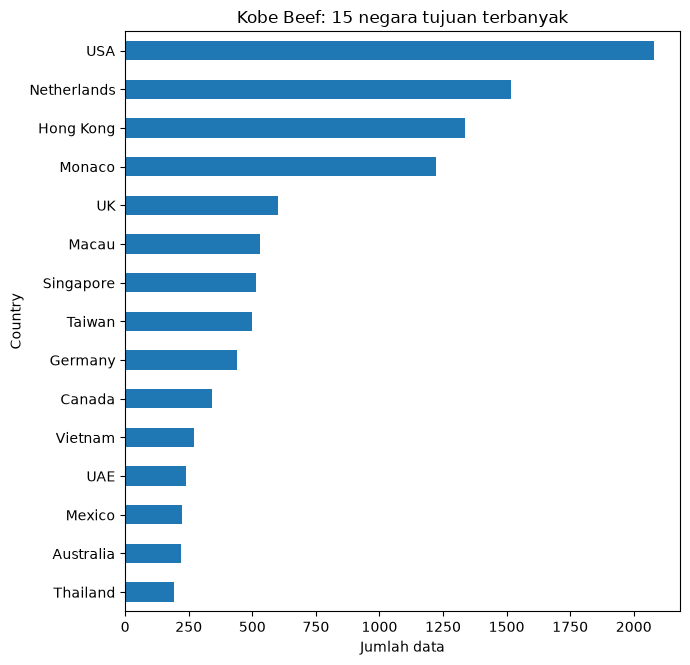

In [15]:
cek_label(df_kobe["Country"], "Kobe Beef: 15 negara tujuan terbanyak", maks=15)
catat(6, "Kobe Beef Global Distribution", "Multi-class", "Country", df_kobe["Country"].nunique(),
      len(df_kobe), "26 negara tujuan, sangat tidak seimbang")

**Alasan:** satu baris = satu pengiriman ke satu negara, jadi bukan multi-label. Jumlah negara lebih dari 2, jadi **multi-class**.
Beberapa negara (misalnya Spain, Belgium, Qatar) datanya sangat sedikit, jadi kelasnya tidak seimbang.

---
## 7. MULTI-LABEL CLASSIFICATION (boleh lebih dari satu label)
Satu data bisa punya **beberapa label sekaligus**. Di ketiga dataset ini, labelnya tersimpan dalam **satu sel**, misalnya `Drama|Comedy` atau `Economic,Negotiation,Political`.
Supaya bisa dihitung, isi sel dipecah menjadi daftar label, lalu diubah menjadi kolom 0/1 untuk tiap label (dengan `pd.get_dummies`).

### 7.1 Movie Genres Overview
**Isi dataset:** judul film, ringkasan cerita (`overview`), dan genre film.

**Kolom label:** `genre`. Isinya teks yang bentuknya seperti daftar, contohnya `['Drama', 'Comedy', 'Romance', 'Crime']` (4 genre sekaligus). Jadi **multi-label**.
Karena masih berupa teks, dibuat **label turunan** `genre_list` (daftar genre yang sebenarnya).

In [16]:
df_mgo = baca_csv("movies.csv")
info_dasar(df_mgo)
print("\nContoh isi kolom genre asli (masih berupa teks):")
display(df_mgo["genre"].head(3).to_frame())

Jumlah baris : 9466
Jumlah kolom : 3
Nama kolom   : ['title', 'overview', 'genre']

Contoh 3 baris pertama:


,title,overview,genre
0,Ariel,After the coal mine he works at clos...,"['Drama', 'Comedy', 'Romance', 'Crime']"
1,Shadows in Paradise,"Nikander, a rubbish collector and wo...","['Drama', 'Comedy', 'Romance']"
2,Four Rooms,It's Ted the Bellhop's first night o...,['Comedy']



Data kosong (NaN) per kolom:


,jumlah_kosong
overview,1



Contoh isi kolom genre asli (masih berupa teks):


,genre
0,"['Drama', 'Comedy', 'Romance', 'Crime']"
1,"['Drama', 'Comedy', 'Romance']"
2,['Comedy']


**Aturan pembuatan label turunan:**
1. Ambil semua kata di dalam tanda kutip pada teks `genre` (itu nama genre-nya).
2. Baris yang isinya `[nan]` (artinya genre kosong) tidak punya label, jadi **dibuang**.

Baris tanpa genre (dibuang): 3
Kolom label              : genre_list
Jumlah data yang dipakai : 9463
Jumlah label unik        : 18
Rata-rata label per data : 2.61
Paling banyak label/data : 7
Data dengan >1 label     : 85.4%

10 label paling sering muncul:


,jumlah
Drama,4220
Comedy,3432
Thriller,2551
Action,2207
Romance,1608
Adventure,1585
Crime,1428
Horror,1357
Science Fiction,1158
Fantasy,1090


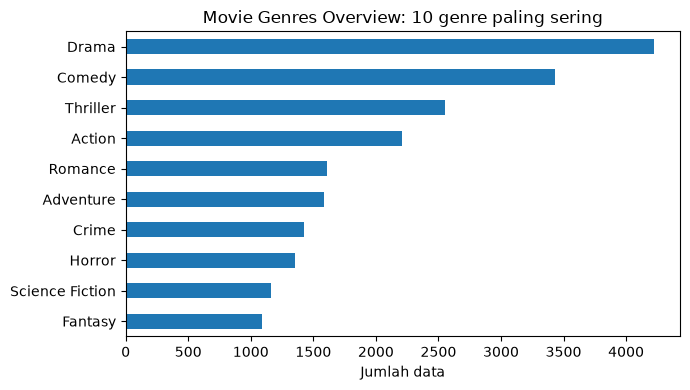


Contoh hasil pemecahan label (1 = punya genre tsb):


,Action,Adventure,Animation,Comedy,Crime,Drama,Family,Fantasy
0,0,0,0,1,1,1,0,0
1,0,0,0,1,0,1,0,0
2,0,0,0,1,0,0,0,0


In [17]:
def baca_genre_teks(teks):
    return [g.strip() for g in re.findall(r"'([^']+)'", str(teks))]


genre_mgo = df_mgo["genre"].apply(baca_genre_teks)
genre_mgo.name = "genre_list"
print(f"Baris tanpa genre (dibuang): {(genre_mgo.str.len() == 0).sum()}")

matriks_mgo, per_baris_mgo = cek_multilabel(genre_mgo, "Movie Genres Overview: 10 genre paling sering")
print("\nContoh hasil pemecahan label (1 = punya genre tsb):")
display(matriks_mgo.iloc[:3, :8])
catat(7, "Movie Genres Overview", "Multi-label", "genre (turunan: teks list dipecah)", matriks_mgo.shape[1],
      len(matriks_mgo), f"rata-rata {per_baris_mgo.mean():.2f} genre per film")

**Alasan:** satu film biasanya punya lebih dari satu genre (misalnya `Drama` dan `Comedy` sekaligus), jadi labelnya tidak bisa dipilih satu saja. Ini **multi-label**.

### 7.2 Movie Dataset with IDs and Genre Tags
**Isi dataset:** ID film, judul (beserta tahun), dan genre film. Bentuknya mirip data MovieLens.

**Kolom label:** `genres`, contohnya `Adventure|Animation|Children|Comedy|Fantasy` (5 genre sekaligus, dipisah tanda `|`). Jadi **multi-label**.

In [18]:
df_mmg = baca_csv("movie_metadata_genres.csv")
info_dasar(df_mmg)

Jumlah baris : 27278
Jumlah kolom : 3
Nama kolom   : ['movieId', 'title', 'genres']

Contoh 3 baris pertama:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|...
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance



Data kosong (NaN) per kolom:
Tidak ada data kosong.


**Aturan pembersihan:** nilai `(no genres listed)` artinya film tidak punya genre, jadi bukan label. Nilai ini dibuang, dan film yang tidak punya genre lain ikut **dibuang** dari analisis label.

Film tanpa genre (dibuang): 246
Kolom label              : genres_list
Jumlah data yang dipakai : 27032
Jumlah label unik        : 19
Rata-rata label per data : 2.00
Paling banyak label/data : 10
Data dengan >1 label     : 60.9%

10 label paling sering muncul:


,jumlah
Drama,13344
Comedy,8374
Thriller,4178
Romance,4127
Action,3520
Crime,2939
Horror,2611
Documentary,2471
Adventure,2329
Sci-Fi,1743


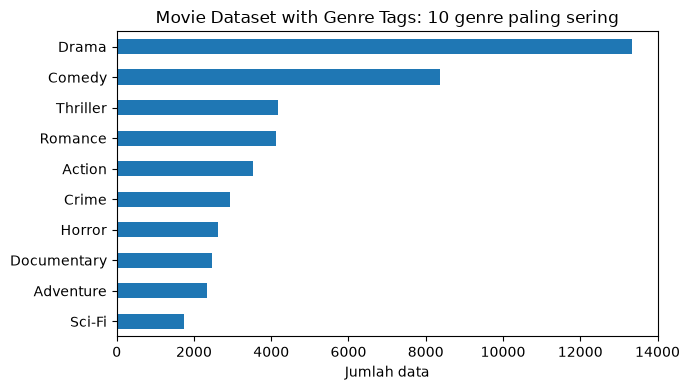


Contoh hasil pemecahan label (1 = punya genre tsb):


,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama
0,0,1,1,1,1,0,0,0
1,0,1,0,1,0,0,0,0
2,0,0,0,0,1,0,0,0


In [19]:
genre_mmg = df_mmg["genres"].str.split("|").apply(lambda daftar: [g for g in daftar if g != "(no genres listed)"])
genre_mmg.name = "genres_list"
print(f"Film tanpa genre (dibuang): {(genre_mmg.str.len() == 0).sum()}")

matriks_mmg, per_baris_mmg = cek_multilabel(genre_mmg, "Movie Dataset with Genre Tags: 10 genre paling sering")
print("\nContoh hasil pemecahan label (1 = punya genre tsb):")
display(matriks_mmg.iloc[:3, :8])
catat(8, "Movie Dataset with IDs and Genre Tags", "Multi-label", "genres (dipisah tanda |)", matriks_mmg.shape[1],
      len(matriks_mmg), f"rata-rata {per_baris_mmg.mean():.2f} genre per film")

**Alasan:** satu film bisa punya beberapa genre sekaligus, misalnya `Comedy|Romance`. Jadi ini **multi-label**.

### 7.3 Board Games Dataset
**Isi dataset:** data permainan papan (nama, deskripsi, jumlah pemain, lama bermain, usia minimal, tahun terbit, desainer, kategori, mekanik, penerbit, rating).

**Kolom label:** `category`, contohnya `Economic,Negotiation,Political` (3 kategori sekaligus, dipisah koma). Jadi **multi-label**.
Kolom `mechanic` (cara bermain) juga berisi banyak nilai, tetapi yang dipilih `category` karena paling mewakili jenis permainan.

In [20]:
df_bg = baca_csv("board_games.csv")
info_dasar(df_bg, kolom_contoh=["name", "year_published", "category", "mechanic"])

Jumlah baris : 10532
Jumlah kolom : 22
Nama kolom   : ['game_id', 'description', 'image', 'max_players', 'max_playtime', 'min_age', 'min_players', 'min_playtime', 'name', 'playing_time', 'thumbnail', 'year_published', 'artist', 'category', 'compilation', 'designer', 'expansion', 'family', 'mechanic', 'publisher', 'average_rating', 'users_rated']

Contoh 3 baris pertama:


,name,year_published,category,mechanic
0,Die Macher,1986,"Economic,Negotiation,Political","Area Control / Area Influence,Auctio..."
1,Dragonmaster,1981,"Card Game,Fantasy",Trick-taking
2,Samurai,1998,"Abstract Strategy,Medieval","Area Control / Area Influence,Hand M..."



Data kosong (NaN) per kolom:


,jumlah_kosong
image,1
thumbnail,1
artist,2773
category,94
compilation,10122
designer,126
expansion,7780
family,2808
mechanic,950
publisher,3


**Aturan pembersihan:** baris yang `category`-nya kosong **dibuang** karena tidak punya label. Sisanya dipecah berdasarkan tanda koma.

Game tanpa kategori (dibuang): 94
Kolom label              : category_list
Jumlah data yang dipakai : 10438
Jumlah label unik        : 83
Rata-rata label per data : 2.63
Paling banyak label/data : 14
Data dengan >1 label     : 81.7%

10 label paling sering muncul:


,jumlah
Card Game,2981
Wargame,2034
Fantasy,1218
Fighting,900
Economic,878
Science Fiction,850
Dice,838
Party Game,833
Abstract Strategy,710
Children's Game,704


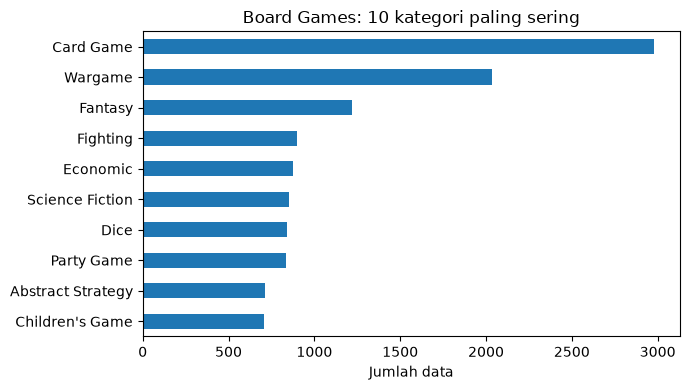


Contoh hasil pemecahan label (1 = punya kategori tsb):


,Abstract Strategy,Action / Dexterity,Adventure,Age of Reason,American Civil War,American Indian Wars,American Revolutionary War,American West
0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0


In [21]:
kategori_bg = df_bg["category"].dropna().str.split(",").apply(lambda daftar: [k.strip() for k in daftar if k.strip()])
kategori_bg.name = "category_list"
print(f"Game tanpa kategori (dibuang): {df_bg['category'].isna().sum()}")

matriks_bg, per_baris_bg = cek_multilabel(kategori_bg, "Board Games: 10 kategori paling sering")
print("\nContoh hasil pemecahan label (1 = punya kategori tsb):")
display(matriks_bg.iloc[:3, :8])
catat(9, "Board Games Dataset", "Multi-label", "category (dipisah koma)", matriks_bg.shape[1],
      len(matriks_bg), f"rata-rata {per_baris_bg.mean():.2f} kategori per game")

**Alasan:** satu game bisa masuk beberapa kategori sekaligus (misalnya `Card Game` dan `Fantasy`), jadi labelnya lebih dari satu. Ini **multi-label**.

---
## 8. Perbandingan 9 dataset
Tabel di bawah dibuat otomatis dari hasil pemeriksaan di atas.

In [22]:
tabel_ringkasan = pd.DataFrame(ringkasan).set_index("No")
display(tabel_ringkasan)

,Dataset,Jenis,Kolom label,Jumlah kelas/label,Jumlah baris,Catatan
No,,,,,,
1,NetFlix,Binary,type,2,7787,Movie vs TV Show (tidak seimbang)
2,Total Anime Movie Releases 2027,Binary,is_franchise_sequel,2,1000,"0 = bukan sekuel, 1 = sekuel"
3,One Piece Live Action IMDB Reviews,Binary,label_sentimen (turunan dari Rating),2,870,Positif (rating 7-10) vs Negatif (ra...
4,Cars Datasets 2025,Multi-class,kelompok_bahan_bakar (turunan dari F...,5,1218,Petrol / Diesel / Electric / Hybrid-...
5,Top Games Dataset,Multi-class,Genre,14,5000,"14 genre, jumlah tiap genre relatif ..."
6,Kobe Beef Global Distribution,Multi-class,Country,26,10783,"26 negara tujuan, sangat tidak seimbang"
7,Movie Genres Overview,Multi-label,genre (turunan: teks list dipecah),18,9463,rata-rata 2.61 genre per film
8,Movie Dataset with IDs and Genre Tags,Multi-label,genres (dipisah tanda |),19,27032,rata-rata 2.00 genre per film
9,Board Games Dataset,Multi-label,category (dipisah koma),83,10438,rata-rata 2.63 kategori per game


In [23]:
tabel_ringkasan.groupby("Jenis")["Dataset"].apply(list).to_frame("Dataset di jenis ini")

,Dataset di jenis ini
Jenis,
Binary,"[NetFlix, Total Anime Movie Releases..."
Multi-class,"[Cars Datasets 2025, Top Games Datas..."
Multi-label,"[Movie Genres Overview, Movie Datase..."


### Perbedaan ketiga jenis klasifikasi (berdasarkan dataset di atas)

| | Binary | Multi-class | Multi-label |
|---|---|---|---|
| **Jumlah pilihan** | 2 | 3 atau lebih | 2 atau lebih |
| **Satu data boleh punya berapa label?** | 1 | 1 | Boleh banyak |
| **Contoh dari dataset** | Netflix: `Movie` atau `TV Show` | Top Games: 1 genre dari 14 | Movie Genres Overview: `Drama, Comedy, Romance, Crime` |
| **Bentuk isi kolom label** | 2 nilai | 1 nilai dari banyak pilihan | Beberapa nilai dalam satu sel |
| **Perlu label turunan?** | Reviews (dari rating) | Cars (dari jenis bahan bakar) | Movie Genres Overview (teks list dipecah) |

## 9. Asal dataset

Semua dataset diunduh dari **Kaggle**. Nama dataset sesuai judul di halaman Kaggle masing-masing, dan tiap tautan bisa diklik langsung ke halaman datasetnya.

| No | Nama dataset | File CSV | Sumber (Kaggle) |
|---|---|---|---|
| 1 | Netflix | `NetFlix.csv` | [kaggle.com/datasets/imtkaggleteam/netflix](https://www.kaggle.com/datasets/imtkaggleteam/netflix) |
| 2 | Total Anime Movie Releases in 2027 | `total_anime_movie_releases_2027_dataset.csv` | [kaggle.com/datasets/abacilla/total-anime-movie-releases-in-2027](https://www.kaggle.com/datasets/abacilla/total-anime-movie-releases-in-2027) |
| 3 | One Piece Live Action IMDB Reviews | `reviews.csv` | [kaggle.com/datasets/itsnobita/one-piece-live-action-imdb-reviews](https://www.kaggle.com/datasets/itsnobita/one-piece-live-action-imdb-reviews) |
| 4 | Cars Datasets (2025) | `Cars Datasets 2025.csv` | [kaggle.com/datasets/abdulmalik1518/cars-datasets-2025](https://www.kaggle.com/datasets/abdulmalik1518/cars-datasets-2025) |
| 5 | Top Games Dataset | `games_dataset.csv` | [kaggle.com/datasets/waqi786/top-games-dataset](https://www.kaggle.com/datasets/waqi786/top-games-dataset) |
| 6 | Kobe Beef Global Distribution | `kobe_beef_distribution (5).csv` | [kaggle.com/datasets/betweentherows/kobe-beef-global-distribution](https://www.kaggle.com/datasets/betweentherows/kobe-beef-global-distribution) |
| 7 | Movie Genres Overview | `movies.csv` | [kaggle.com/datasets/hetpatel01/movie-genres-overview](https://www.kaggle.com/datasets/hetpatel01/movie-genres-overview) |
| 8 | Movie Dataset with IDs and Genre Tags | `movie_metadata_genres.csv` | [kaggle.com/datasets/gzdekzlkaya/movie-dataset-with-ids-and-genre-tags](https://www.kaggle.com/datasets/gzdekzlkaya/movie-dataset-with-ids-and-genre-tags) |
| 9 | Board Games Dataset | `board_games.csv` | [kaggle.com/datasets/sujaykapadnis/board-games](https://www.kaggle.com/datasets/sujaykapadnis/board-games) |

## 10. Kesimpulan

**Kesimpulan umum**

1. **Binary Classification** (2 kelas) dipakai pada **NetFlix** (`Movie` / `TV Show`), **Anime Movie 2027** (`sekuel` / `bukan sekuel`), dan **One Piece Reviews** (`Positif` / `Negatif`).
2. **Multi-class Classification** (banyak kelas, pilih satu) dipakai pada **Cars 2025** (kelompok bahan bakar, 5 kelas), **Top Games** (genre, 14 kelas), dan **Kobe Beef** (negara tujuan, 26 kelas).
3. **Multi-label Classification** (boleh banyak label sekaligus) dipakai pada **Movie Genres Overview**, **Movie Dataset with Genre Tags** (genre film), dan **Board Games** (kategori game). Ketiganya punya rata-rata 2 sampai 3 label per data.
4. Pembagian dibuat dari **isi kolom label**, bukan dari tema dataset. Contohnya, Top Games (satu genre per game) masuk **multi-class**, sedangkan Movie Genres Overview (banyak genre per film) masuk **multi-label**, walaupun sama-sama tentang genre.
5. Tiga label dibuat sendiri (**label turunan**): `label_sentimen` (Reviews), `kelompok_bahan_bakar` (Cars), dan `genre_list` (Movie Genres Overview). Aturan pembuatannya sudah dijelaskan di bagian masing-masing.
6. Beberapa dataset punya **kelas yang tidak seimbang** (misalnya Reviews 86% Positif, Netflix lebih banyak Movie, Kobe Beef didominasi beberapa negara). Ini perlu diperhatikan kalau nanti dipakai untuk melatih model.

**Kenapa masuk jenis tersebut, dan rujukannya**

| Jenis | Kenapa dataset masuk ke sini | Rujukan |
|---|---|---|
| **Binary** | Labelnya hanya punya 2 nilai dan tiap data hanya masuk ke satu nilai. | [1] |
| **Binary (label turunan)** | Rating 1-10 diubah jadi 2 kelas (Positif / Negatif). Cara mengubah rating bintang jadi dua kelas juga dipakai pada penelitian sentimen ulasan. Batas 7 pada tugas ini adalah pilihan sendiri karena skalanya 1-10. | [7], [8] |
| **Multi-class** | Labelnya punya 3 kelas atau lebih, tetapi satu data tetap hanya punya satu label. | [1], [2], [4] |
| **Multi-label** | Satu data bisa punya beberapa label sekaligus, dan labelnya dicatat sebagai daftar. Genre film adalah contoh yang paling umum. | [2], [3], [4], [5], [6] |
| **Kelas tidak seimbang** | Jumlah data antar kelas timpang, sehingga akurasi saja kurang bisa dipercaya. | [2], [3], [7] |

## 11. Referensi (2023-2026)
| No | Referensi | Tahun | Dipakai untuk |
|---|---|---|---|
| [1] | Kumar, A. (2024). *Difference: Binary vs Multiclass vs Multilabel Classification*. Vitalflux. Terakhir diperbarui 13 September 2024. https://vitalflux.com/difference-binary-multi-class-multi-label-classification/ | 2024 | Penjelasan sederhana ketiga jenis klasifikasi. Ada contoh film berlabel `comedy` dan `drama` sekaligus (multi-label). |
| [2] | GeeksforGeeks. (2026). *Multiclass Classification vs Multi-label Classification*. Terakhir diperbarui 6 Januari 2026. https://www.geeksforgeeks.org/machine-learning/multiclass-classification-vs-multi-label-classification/ | 2026 | Beda multi-class (satu label) dan multi-label (banyak label). Ada contoh genre film dan catatan soal label tidak seimbang. |
| [3] | scikit-learn developers. *1.12. Multiclass and multioutput algorithms* (dokumentasi versi stable, diakses 7 November 2026). https://scikit-learn.org/stable/modules/multiclass.html | 2026 | Tabel resmi perbedaan multiclass dan multilabel. Multilabel dicatat sebagai indikator 0/1 per label, seperti yang dibuat di notebook ini. |
| [4] | Shaukat, F., Ejaz, N., Ashraf, Z., Alnfiai, M. M., Alotaibi, N. N., & Alnefaie, S. M. M. (2025). An interpretable multi-transformer ensemble for text-based movie genre classification. *PeerJ Computer Science, 11*, e2945. https://doi.org/10.7717/peerj-cs.2945 | 2025 | Menyebut film bisa masuk beberapa genre sekaligus, sehingga klasifikasi genre film adalah masalah multi-label. Akses terbuka. |
| [5] | Shaukat, F., Ejaz, N., Kamal, R., Alkhalifah, T., Aslam, S., & Mu, M. (2025). Multi-Label Movie Genre Classification with Attention Mechanism on Movie Plots. *Computers, Materials & Continua, 83*(3), 5595-5622. https://doi.org/10.32604/cmc.2025.061702 | 2025 | Contoh penelitian multi-label genre film dari ringkasan cerita. Salah satu datasetnya berbasis MovieLens, mirip dataset nomor 8. |
| [6] | Google for Developers. (2025). *Datasets: Class-imbalanced datasets* (Machine Learning Crash Course). Terakhir diperbarui 28 Agustus 2025. https://developers.google.com/machine-learning/crash-course/overfitting/imbalanced-datasets | 2025 | Arti kelas mayoritas dan minoritas, serta kenapa akurasi kurang cocok untuk data yang tidak seimbang (Reviews, Netflix, Kobe Beef). |
| [7] | Ashbaugh, L., & Zhang, Y. (2024). *A Comparative Study of Sentiment Analysis on Customer Reviews Using Machine Learning and Deep Learning*. Preprints.org (belum melalui peer review), 11 November 2024. https://doi.org/10.20944/preprints202411.0741.v1 | 2024 | Memakai rating bintang sebagai pengganti (proxy) sentimen ulasan, dan mencatat rating yang condong ke 4-5 bintang (tidak seimbang). |
| [8] | Sentiment Analysis Based on RoBERTa for Amazon Review: An Empirical Study on Decision Making (2024). arXiv:2411.00796. https://arxiv.org/abs/2411.00796 | 2024 | Contoh mengubah rating bintang jadi binary: 1-3 bintang negatif, 4-5 bintang positif. |

